# U.S. Fertility: FPCA and Functional Autoencoder

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from scipy.interpolate import BSpline, PchipInterpolator
from IPython.display import display

# The original data file is required
DATA_PATH = None
PDF_NAME = "fertility_forecasts.pdf" 
TRAIN_END = 2018
TEST_YEARS = np.arange(2019, 2024)
K = 3
SEED = 743

FOLDS = [(2008, np.arange(2009, 2014)), (2013, np.arange(2014, 2019))]
FOLD_WEIGHTS = np.array([0.35, 0.65])

# Use the same latent VAR(1) estimator and ridge search for both methods.
VAR_RIDGES = [0.05, 0.10, 0.30, 1.0]

# FPCA
FPCA_BASIS = [22, 25]
FPCA_PENALTIES = [1e-6, 1e-4, 1e-3, 1e-2]

# FAE 
# Positive lambda in EVERY candidate: smoothness is inside the training loss.
FAE_CONFIGS = [
    dict(name="Quartic22a", basis=22, degree=4,
         lam=0.008, lr=3e-4, init_sd=0.50),
]

FAE_SEEDS = [2026]
FAE_EPOCHS = [5000]
FAE_HIDDEN = 100
FAE_WEIGHT_DECAY = 1e-6

assert all(cfg["lam"] > 0 for cfg in FAE_CONFIGS)
assert len({cfg["name"] for cfg in FAE_CONFIGS}) == len(FAE_CONFIGS)
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.rcParams.update({"font.size": 11})

## Fertility data and split

Rows in the CSV are ages; columns are years. We transpose only so each row of the model input represents one yearly curve.

In [2]:
paths = ([Path(DATA_PATH)] if DATA_PATH else []) + [
    Path("USAfertility.csv"),
    Path("data/USAfertility.csv"),
    Path("FAE-Time Series/USAfertility.csv"),
    Path(r"D:\Marquette\FAE Codes\FAE-Time Series\USAfertility.csv"),
]
source = next((p for p in paths if p.is_file()), None)
if source is None:
    raise FileNotFoundError("Place USAfertility.csv beside this notebook, or set DATA_PATH.")

raw = pd.read_csv(source)
if "Age" not in raw.columns:
    raise ValueError("The CSV must have an 'Age' column.")
year_labels = [c for c in raw.columns if c != "Age"]
years_unsorted = np.asarray([int(c) for c in year_labels], dtype=int)
order = np.argsort(years_unsorted)
years = years_unsorted[order]
ages = pd.to_numeric(raw["Age"], errors="raise").to_numpy(float)
rates = raw[year_labels].apply(pd.to_numeric, errors="raise").to_numpy(float)[:, order]
if not (np.isfinite(ages).all() and np.isfinite(rates).all()):
    raise ValueError("Input data contain missing or nonfinite values.")
if not (np.diff(ages) > 0).all() or not (np.diff(years) > 0).all():
    raise ValueError("Ages and years must be strictly increasing and unique.")

X = rates.T
train_mask = years <= TRAIN_END
test_mask = np.isin(years, TEST_YEARS)
train_years, X_train = years[train_mask], X[train_mask]
test_years, X_test = years[test_mask], X[test_mask]
assert np.array_equal(test_years, TEST_YEARS)
assert np.array_equal(X_test.T, rates[:, test_mask])
for cutoff, future_years in FOLDS:
    assert np.array_equal(years[np.isin(years, future_years)], future_years)
    assert (years <= cutoff).sum() > K + 2
print(f"Data: {len(years)} years ({years[0]}–{years[-1]}), {len(ages)} ages ({ages[0]:g}–{ages[-1]:g})")
print(f"Training: {train_years[0]}–{train_years[-1]} | Test: {test_years[0]}–{test_years[-1]}")

Data: 91 years (1933–2023), 42 ages (13–54)
Training: 1933–2018 | Test: 2019–2023


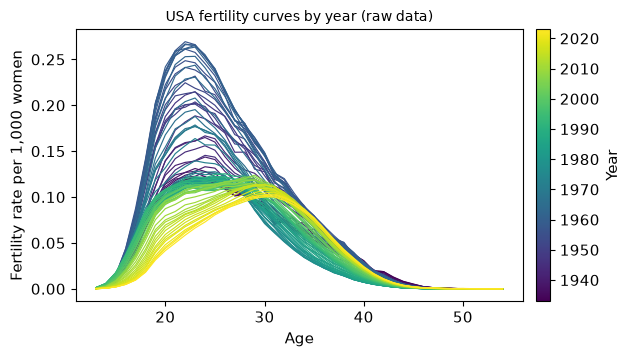

In [3]:
# Plot original USA fertility curves by year
fig, ax = plt.subplots(figsize=(6.5, 3.7))

cmap = plt.get_cmap("viridis")
norm = plt.Normalize(vmin=years.min(), vmax=years.max())

for j, year in enumerate(years):
    ax.plot(
        ages, rates[:, j],
        color=cmap(norm(year)),
        linewidth=0.85
    )

ax.set_title("USA fertility curves by year (raw data)", fontsize=10)
ax.set_xlabel("Age")
ax.set_ylabel("Fertility rate per 1,000 women")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.025)
cbar.set_label("Year")
cbar.set_ticks(np.arange(1940, 2030, 10))

plt.tight_layout()
plt.show()

## Shared B-spline and VAR(1) computations

Both methods use a fixed B-spline basis on the age domain and the same VAR(1). Age rescaling is used to define basis functions and numerical integration weights.

In [4]:
u = (ages - ages.min()) / (ages.max() - ages.min())
w = np.empty(len(u), float)
w[0], w[-1] = (u[1] - u[0])/2, (u[-1] - u[-2])/2
w[1:-1] = (u[2:] - u[:-2])/2


def bspline_matrix(n_basis, degree=3, right_pad=0.0):
    n_inner = n_basis - degree - 1
    right = 1.0 + right_pad

    inside = np.linspace(0, right, n_inner + 2)[1:-1]
    knots = np.r_[
        np.zeros(degree + 1),
        inside,
        np.full(degree + 1, right)
    ]

    return BSpline.design_matrix(
        u, knots, degree
    ).toarray().astype(float)


def var1_forecast(H, steps, ridge):
    H = np.asarray(H, float)
    mu = H.mean(axis=0)
    sd = np.maximum(H.std(axis=0), 1e-8)
    Z = (H - mu) / sd
    design = np.column_stack((np.ones(len(Z) - 1), Z[:-1]))
    target = Z[1:]
    penalty = np.diag([1e-8] + [float(ridge)] * H.shape[1])
    coefficient = np.linalg.solve(design.T @ design + penalty, design.T @ target)
    intercept, A = coefficient[0], coefficient[1:].T
    state = Z[-1].copy()
    future = np.empty((steps, H.shape[1]))
    for h in range(steps):
        state = intercept + A @ state
        future[h] = state * sd + mu
    return future

## Smooth FPCA + VAR(1)

In [5]:
def smooth_fpca_forecast(X_history, steps, n_basis, lam, ridge):
    B = bspline_matrix(n_basis, degree=3)
    D2 = np.diff(np.eye(n_basis), n=2, axis=0)
    gram = B.T @ (w[:, None] * B)
    system = gram + lam * (D2.T @ D2) + 1e-10 * np.eye(n_basis)
    coef = np.linalg.solve(system, B.T @ (w[:, None] * X_history.T)).T
    X_spline = coef @ B.T

    mean_curve = X_spline.mean(axis=0)
    centered = X_spline - mean_curve
    _, _, Vt = np.linalg.svd(centered * np.sqrt(w)[None, :], full_matrices=False)
    phi = Vt[:K] / np.sqrt(w)[None, :]
    scores = (centered * w[None, :]) @ phi.T
    scores_future = var1_forecast(scores, steps, ridge)
    return mean_curve[None, :] + scores_future @ phi

## Functional autoencoder 

The encoder is `B → 100 → 3`; decoder is `3 → 100 → B` with ReLU hidden layers and linear output layers.
Its loss function is `reconstruction MSE + lambda * smoothness penalty. 

In [6]:
class FunctionalAutoencoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        n_basis = int(cfg["basis"])
        B = torch.as_tensor(
            bspline_matrix(
                n_basis,
                cfg["degree"],
                right_pad=cfg.get("right_pad", 0.0)
            ),
            dtype=torch.float32
        )
        W = torch.as_tensor(w, dtype=torch.float32)
        self.register_buffer("feature_map", B * W[:, None])
        self.register_buffer("basis", B)
        self.encoder1 = nn.Linear(n_basis, FAE_HIDDEN, bias=False)
        self.encoder2 = nn.Linear(FAE_HIDDEN, K, bias=False)
        self.decoder1 = nn.Linear(K, FAE_HIDDEN, bias=False)
        self.decoder2 = nn.Linear(FAE_HIDDEN, n_basis, bias=False)
        for layer in (self.encoder1, self.encoder2, self.decoder1, self.decoder2):
            nn.init.normal_(layer.weight, mean=0.0, std=cfg["init_sd"])

    def encode(self, x):
        return self.encoder2(torch.relu(self.encoder1(x @ self.feature_map)))

    def decode(self, h):
        b = self.decoder2(torch.relu(self.decoder1(h)))
        return b @ self.basis.T, b

    def forward(self, x):
        prediction, b = self.decode(self.encode(x))
        return prediction, b


def fae_loss(predicted, observed, coef, lam):
    second_difference = coef[:, 2:] - 2 * coef[:, 1:-1] + coef[:, :-2]
    return torch.mean((predicted - observed)**2) + lam * torch.sum(second_difference**2, dim=1).mean()


@torch.no_grad()
def fae_forecast(model, X_history, steps, ridge):
    model.eval()
    history = torch.as_tensor(X_history, dtype=torch.float32)
    H = model.encode(history).cpu().numpy().astype(float)
    H_future = var1_forecast(H, steps, ridge)
    X_future, _ = model.decode(torch.as_tensor(H_future, dtype=torch.float32))
    return X_future.cpu().numpy().astype(float)


def fit_fae(X_history, cfg, seed, epochs):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = FunctionalAutoencoder(cfg)
    optim = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=FAE_WEIGHT_DECAY)
    data = torch.as_tensor(X_history, dtype=torch.float32)
    for epoch in range(1, epochs + 1):
        model.train()
        optim.zero_grad()
        prediction, coefficients = model(data)
        loss = fae_loss(prediction, data, coefficients, cfg["lam"])
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f"Training diverged: {cfg['name']}")
        loss.backward()
        optim.step()
    return model


fold_data = []
for cutoff, future_years in FOLDS:
    historical = X[years <= cutoff]
    targets = X[np.isin(years, future_years)]
    fold_data.append((historical, targets))

fpca_trials = []
for bsize in FPCA_BASIS:
    for smooth_lambda in FPCA_PENALTIES:
        for ridge in VAR_RIDGES:
            try:
                errors = [np.mean((smooth_fpca_forecast(hist, len(obs), bsize, smooth_lambda, ridge) - obs)**2)
                          for hist, obs in fold_data]
                fpca_trials.append(dict(basis=bsize, lam=smooth_lambda, ridge=ridge,
                                        val_mse=float(np.dot(FOLD_WEIGHTS, errors))))
            except np.linalg.LinAlgError:
                continue
fpca_ranking = pd.DataFrame(fpca_trials).sort_values("val_mse").reset_index(drop=True)
if fpca_ranking.empty:
    raise RuntimeError("No valid FPCA setting.")
fpca_best = fpca_ranking.iloc[0].to_dict()
print("Selected smooth FPCA:", fpca_best)


fae_records = []
for cfg in FAE_CONFIGS:
    for seed in FAE_SEEDS:
        predictions_by_fold = {}
        for fold_idx, (historical, observed) in enumerate(fold_data):
            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            model = FunctionalAutoencoder(cfg)
            optimizer = torch.optim.Adam(model.parameters(), lr=cfg["lr"],
                                         weight_decay=FAE_WEIGHT_DECAY)
            data = torch.as_tensor(historical, dtype=torch.float32)
            checkpoint_forecasts = {}
            valid_training = True
            for epoch in range(1, max(FAE_EPOCHS) + 1):
                model.train()
                optimizer.zero_grad()
                reconstruction, coef = model(data)
                loss = fae_loss(reconstruction, data, coef, cfg["lam"])
                if not torch.isfinite(loss).item():
                    valid_training = False
                    break
                loss.backward()
                optimizer.step()
                if epoch in FAE_EPOCHS:
                    for ridge in VAR_RIDGES:
                        prediction = fae_forecast(model, historical, len(observed), ridge)
                        if np.isfinite(prediction).all():
                            checkpoint_forecasts[(epoch, ridge)] = prediction
            if not valid_training:
                predictions_by_fold = {}
                break
            predictions_by_fold[fold_idx] = checkpoint_forecasts
        if len(predictions_by_fold) == len(fold_data):
            for epoch in FAE_EPOCHS:
                for ridge in VAR_RIDGES:
                    key = (epoch, ridge)
                    if all(key in predictions_by_fold[i] for i in range(len(fold_data))):
                        errors = [np.mean((predictions_by_fold[i][key] - fold_data[i][1])**2)
                                  for i in range(len(fold_data))]
                        fae_records.append(dict(name=cfg["name"], seed=seed, epochs=epoch,
                                                ridge=ridge, val_mse=float(np.dot(FOLD_WEIGHTS, errors))))
        print(f"Validated: {cfg['name']}, seed={seed}")

fae_ranking = pd.DataFrame(fae_records).sort_values("val_mse").reset_index(drop=True)
if fae_ranking.empty:
    raise RuntimeError("No stable FAE setting; reduce initialization or learning rate.")
fae_best = fae_ranking.iloc[0].to_dict()
fae_config = next(c for c in FAE_CONFIGS if c["name"] == fae_best["name"])
print("\nSelected FAE:", {**fae_config, "seed": int(fae_best["seed"]),
                            "epochs": int(fae_best["epochs"]), "ridge": fae_best["ridge"]})
print("Validation MSE — FPCA: %.8f | FAE: %.8f" % (fpca_best["val_mse"], fae_best["val_mse"]))

Selected smooth FPCA: {'basis': 22.0, 'lam': 0.01, 'ridge': 0.05, 'val_mse': 0.0001658644671693381}
Validated: Quartic22a, seed=2026

Selected FAE: {'name': 'Quartic22a', 'basis': 22, 'degree': 4, 'lam': 0.008, 'lr': 0.0003, 'init_sd': 0.5, 'seed': 2026, 'epochs': 5000, 'ridge': 0.05}
Validation MSE — FPCA: 0.00016586 | FAE: 0.00007595


## 2019–2023 forecasts and MSE

In [7]:
X_fpca = smooth_fpca_forecast(X_train, len(TEST_YEARS),
                              int(fpca_best["basis"]), fpca_best["lam"], fpca_best["ridge"])
fae_model = fit_fae(X_train, fae_config, int(fae_best["seed"]), int(fae_best["epochs"]))
X_fae = fae_forecast(fae_model, X_train, len(TEST_YEARS), fae_best["ridge"])
assert X_fpca.shape == X_fae.shape == X_test.shape

mse_fpca = float(np.mean((X_fpca - X_test)**2))
mse_fae = float(np.mean((X_fae - X_test)**2))
variance_test = float(np.var(X_test))
summary = pd.DataFrame({
    "Method": ["Smooth FPCA + VAR(1)", "Penalized FAE + VAR(1)"],
    "MSE": [mse_fpca, mse_fae],
    "relMSE": [mse_fpca / variance_test, mse_fae / variance_test],
})
print(summary.to_string(index=False, formatters={"MSE": "{:.8f}".format, "relMSE": "{:.6f}".format}))
print("FAE MSE reduction vs FPCA: %.2f%%" % (100 * (mse_fpca - mse_fae) / mse_fpca))
print("Test winner:", "FAE" if mse_fae < mse_fpca else ("FPCA" if mse_fpca < mse_fae else "Tie"))

                Method        MSE   relMSE
  Smooth FPCA + VAR(1) 0.00006604 0.044822
Penalized FAE + VAR(1) 0.00000899 0.006101
FAE MSE reduction vs FPCA: 86.39%
Test winner: FAE


## Observed vs predicted fertility curves

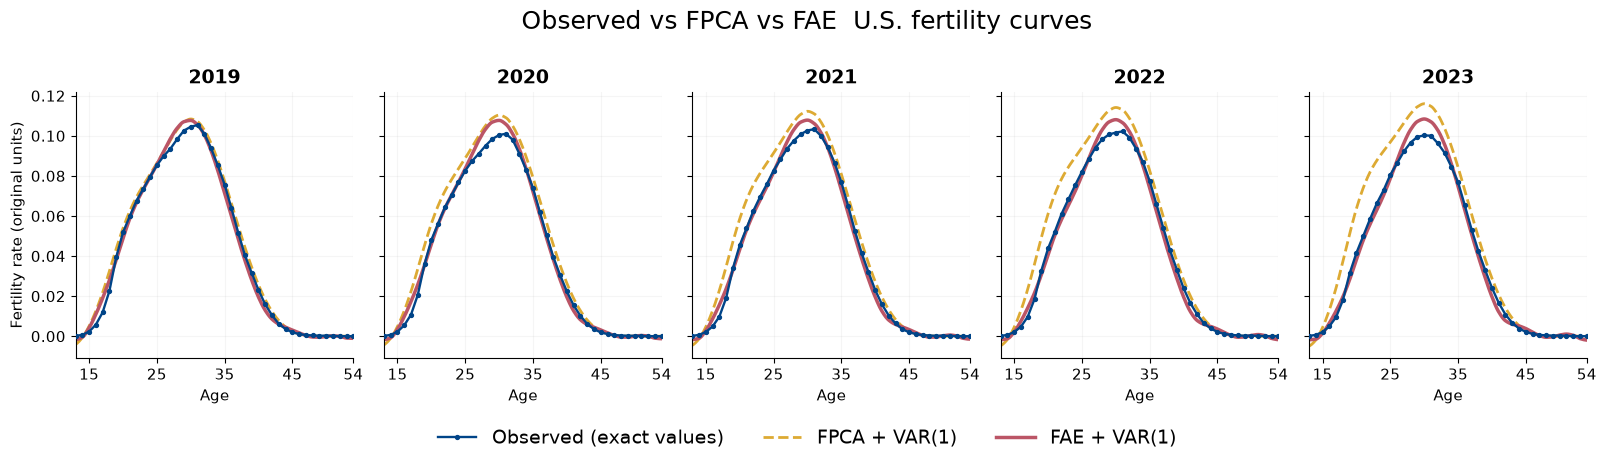

Figure saved: fertility_forecasts.pdf


In [8]:
plot_ages = np.linspace(ages.min(), ages.max(), 450)
fig, axes = plt.subplots(1, 5, figsize=(19.5, 4.3), sharex=True, sharey=True)
for i, (ax, year) in enumerate(zip(axes, test_years)):
    ax.plot(ages, X_test[i], color="#004488", lw=1.7, marker="o", ms=2.8,
            label="Observed (exact values)", zorder=5)
    ax.plot(plot_ages, PchipInterpolator(ages, X_fpca[i])(plot_ages),
            color="#DDAA33", ls="--", lw=2.0, label="FPCA + VAR(1)")
    ax.plot(plot_ages, PchipInterpolator(ages, X_fae[i])(plot_ages),
            color="#BB5566", lw=2.5, label="FAE + VAR(1)")
    ax.set_title(str(int(year)), color="black", fontweight="bold", fontsize=14)
    ax.set_xlim(ages.min(), ages.max())
    ax.set_xticks([15, 25, 35, 45, 54])
    ax.set_xlabel("Age")
    ax.grid(alpha=0.12)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Fertility rate (original units)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.04), fontsize=14)
fig.suptitle("Observed vs FPCA vs FAE  U.S. fertility curves", y=1.02, fontsize=18)
fig.subplots_adjust(wspace=0.11, bottom=0.21, top=0.83)
fig.savefig(PDF_NAME, format="pdf", bbox_inches="tight")
plt.show()
print("Figure saved:", PDF_NAME)